In [14]:
import pandas as pd
df = pd.read_csv(r"Demo.csv")

In [15]:
df.head()

,Order ID,Region,Sales Channel,Product Category,Units Sold,Unit Price,Discount %,Delivery Days,Customer Rating,Returned?,Order Month
0,ORD-1001,WEST,Retail,Stationery,6,299,5%,4.0,3.0,No,Jun
1,ORD-1002,WEST,Online,Home Essentials,30,499,0%,8.0,3.0,No,Feb
2,ORD-1003,West,Partner,Personal Care,22,499,15%,2.0,5.0,No,Mar
3,ORD-1004,north,Online,Electronics,14,199,20%,6.0,5.0,No,Mar
4,ORD-1005,East,Partner,Office Supplies,10,199,5%,10.0,2.0,Yes,Mar


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          60 non-null     str    
 1   Region            60 non-null     str    
 2   Sales Channel     60 non-null     str    
 3   Product Category  60 non-null     str    
 4   Units Sold        60 non-null     int64  
 5   Unit Price        60 non-null     int64  
 6   Discount %        60 non-null     str    
 7   Delivery Days     59 non-null     float64
 8   Customer Rating   59 non-null     float64
 9   Returned?         60 non-null     str    
 10  Order Month       60 non-null     str    
dtypes: float64(2), int64(2), str(7)
memory usage: 5.3 KB


In [17]:
df.isna().sum()

Order ID            0
Region              0
Sales Channel       0
Product Category    0
Units Sold          0
Unit Price          0
Discount %          0
Delivery Days       1
Customer Rating     1
Returned?           0
Order Month         0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(1)

In [19]:
#checking the duplicate row
df[df.duplicated(keep=False)]

,Order ID,Region,Sales Channel,Product Category,Units Sold,Unit Price,Discount %,Delivery Days,Customer Rating,Returned?,Order Month
18,ORD-1019,North,Online,Office Supplies,5,2499,20%,2.0,5.0,No,Apr
59,ORD-1019,North,Online,Office Supplies,5,2499,20%,2.0,5.0,No,Apr


In [20]:
#removing duplicate values
df = df.drop_duplicates()

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
#checking what the invalid values are
df[df["Delivery Days"].isna() | df["Customer Rating"].isna()]

,Order ID,Region,Sales Channel,Product Category,Units Sold,Unit Price,Discount %,Delivery Days,Customer Rating,Returned?,Order Month
29,ORD-1030,South,Partner,Stationery,7,499,5%,NaN,5.0,No,May
35,ORD-1036,north,Retail,Home Essentials,25,499,15%,7.0,NaN,No,Jan


In [35]:
#standardizes the capitalization
for col in ["Region", "Sales Channel", "Product Category"]:
    df[col] = df[col].str.strip().str.title()

In [37]:
# filling missing delivery time with the average for that region
df["Delivery Days"] = df["Delivery Days"].fillna(
    df.groupby("Region")["Delivery Days"].transform("mean")
)

# filling missing rating with the average for that product category
df["Customer Rating"] = df["Customer Rating"].fillna(
    df.groupby("Product Category")["Customer Rating"].transform("mean")
)

In [39]:
df.groupby("Region")["Delivery Days"].mean().round(2)

Region
East     5.12
North    5.60
South    5.50
West     5.06
Name: Delivery Days, dtype: float64

In [41]:
df.groupby("Product Category")["Customer Rating"].mean().round(2)

Product Category
Electronics        3.69
Home Essentials    3.29
Office Supplies    4.00
Personal Care      3.50
Stationery         3.82
Name: Customer Rating, dtype: float64

In [42]:
# Checking the category values
for col in ["Region", "Sales Channel", "Product Category"]:
    print(col, df[col].unique())

Region <StringArray>
['West', 'North', 'East', 'South']
Length: 4, dtype: str
Sales Channel <StringArray>
['Retail', 'Online', 'Partner']
Length: 3, dtype: str
Product Category <StringArray>
[     'Stationery', 'Home Essentials',   'Personal Care',     'Electronics',
 'Office Supplies']
Length: 5, dtype: str


In [43]:
#fixing office supply and office supplies by combining into one
df["Product Category"] = df["Product Category"].replace({
    "Office Supply": "Office Supplies"
})

In [44]:
#sales by region
df.groupby("Region")["Units Sold"].sum().sort_values(ascending=False)

Region
North    338
West     238
South    120
East     115
Name: Units Sold, dtype: int64

In [45]:
#sales by product category
df.groupby("Product Category")["Units Sold"].sum().sort_values(ascending=False)

Product Category
Home Essentials    229
Electronics        187
Office Supplies    180
Stationery         109
Personal Care      106
Name: Units Sold, dtype: int64

# Bar Charts

<Axes: title={'center': 'Units Sold by Region'}, xlabel='Region', ylabel='Units Sold'>

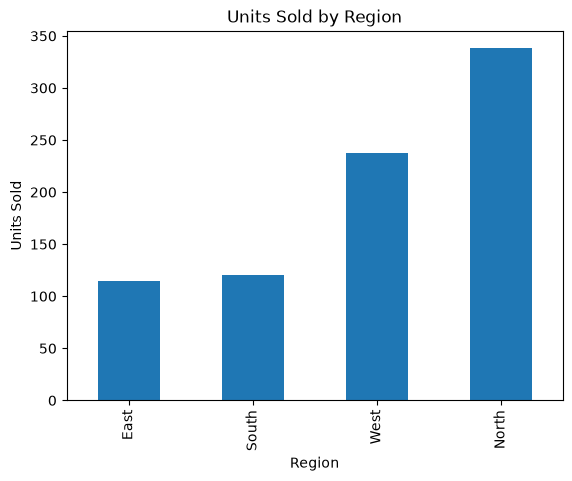

In [46]:
#for regions
df.groupby("Region")["Units Sold"].sum().sort_values().plot(
    kind="bar",
    title="Units Sold by Region",
    ylabel="Units Sold",
    xlabel="Region"
)

--Analysis: *North* region sold the most units followed by west, south and east selling the lowest

<Axes: title={'center': 'Units sold by product'}, xlabel='Products', ylabel='Units sold'>

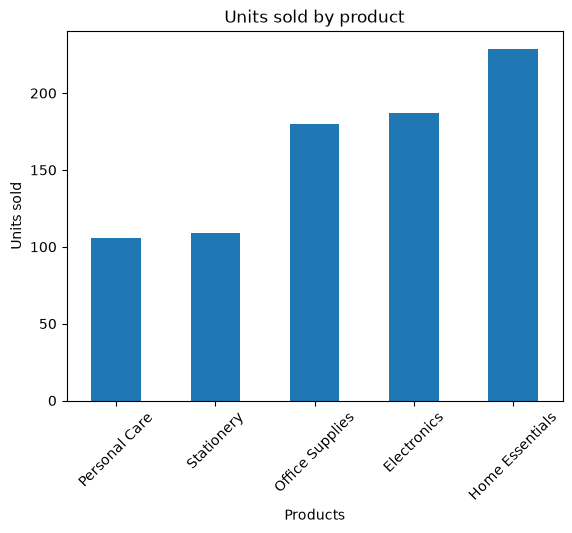

In [47]:
df.groupby("Product Category")["Units Sold"].sum().sort_values().plot(
    kind = "bar",
    title = "Units sold by product",
    ylabel = "Units sold",
    xlabel = "Products",
    rot= 45
)

Analysis: *Home Essentials* Sold the most followed by electronics, office supplies, stationery and personal care selling the lowest

In [48]:
#Making a revenue column

df["Discount Rate"] = (
    df["Discount %"].str.rstrip("%").astype(float) / 100
)

df["Revenue"] = (
    df["Units Sold"] * df["Unit Price"] * (1 - df["Discount Rate"])
)

In [49]:
#revenue by region
df.groupby("Region")["Revenue"].sum().sort_values(ascending=False)

Region
North    249538.4
West     161632.2
South    127008.9
East      83630.1
Name: Revenue, dtype: float64

In [50]:
#Revenue by sales channel
df.groupby("Sales Channel")["Revenue"].sum().sort_values(ascending=False)

Sales Channel
Retail     258687.35
Partner    187659.00
Online     175463.25
Name: Revenue, dtype: float64

In [51]:
# Compare return rates by product category and sales channel
df["Returned Flag"] = df["Returned?"].str.strip().str.title().eq("Yes")
display(
    df.groupby("Product Category")["Returned Flag"]
      .agg(Orders="count", Return_Rate="mean")
      .assign(Return_Rate=lambda x: x["Return_Rate"] * 100)
      .round(1)
      .sort_values("Return_Rate", ascending=False)
)

display(
    df.groupby("Sales Channel")["Returned Flag"]
      .agg(Orders="count", Return_Rate="mean")
      .assign(Return_Rate=lambda x: x["Return_Rate"] * 100)
      .round(1)
      .sort_values("Return_Rate", ascending=False)
)

Sales Channel
Online     22.2
Partner    26.3
Retail      9.1
Name: Returned Flag, dtype: float64

In [52]:
df.groupby("Returned?")[["Delivery Days", "Customer Rating"]].mean().round(1)

,Delivery Days,Customer Rating
Returned?,,
No,4.5,4.1
Yes,9.0,1.9


## Sales and Customer Service Findings

- **Revenue by region:** North had the highest estimated revenue (249,538), followed by West (161,632), South (127,009), and East (83,630).
- **Revenue by sales channel:** Retail had the highest estimated revenue (258,687), followed by Partner (187,659) and Online (175,463).
- **Returns by channel:** Return rates were higher for Partner (26.3%) and Online (22.2%) orders than for Retail orders (9.1%) in this sample.
- **Delivery and ratings:** Returned orders had longer average delivery times (9 days vs. 4.5) and lower average ratings (1.9 vs. 4.1). This is an association in the data; it does not prove that longer delivery times caused returns.

In [56]:
# Analyze sales performance by product category, region, and sales channel
# Calculate total orders, units sold, revenue, average revenue, customer ratings, and return rate
# Sort results by revenue in descending order for easy comparison

df["Returned Flag"] = df["Returned?"].str.strip().str.title().eq("Yes")

def performance_table(group):
    return (
        df.groupby(group)
          .agg(
              Orders=("Order ID", "nunique"),
              Units=("Units Sold", "sum"),
              Revenue=("Revenue", "sum"),
              Avg_Order_Revenue=("Revenue", "mean"),
              Avg_Rating=("Customer Rating", "mean"),
              Return_Rate=("Returned Flag", "mean")
          )
          .assign(Return_Rate=lambda x: x["Return_Rate"] * 100)
          .round(2)
          .sort_values("Revenue", ascending=False)
    )

display(performance_table("Product Category"))
display(performance_table("Region"))
display(performance_table("Sales Channel"))

,Orders,Units,Revenue,Avg_Order_Revenue,Avg_Rating,Return_Rate
Product Category,,,,,,
Office Supplies,14,180,210885.50,15063.25,4.00,14.29
Home Essentials,15,229,162918.10,10861.21,3.29,20.00
Electronics,13,187,104606.55,8046.66,3.69,30.77
Personal Care,6,106,85538.25,14256.38,3.50,16.67
Stationery,11,109,57861.20,5260.11,3.82,9.09


,Orders,Units,Revenue,Avg_Order_Revenue,Avg_Rating,Return_Rate
Region,,,,,,
North,25,338,249538.4,9981.54,3.65,24.00
West,17,238,161632.2,9507.78,3.59,17.65
South,9,120,127008.9,14112.10,4.00,0.00
East,8,115,83630.1,10453.76,3.50,25.00


,Orders,Units,Revenue,Avg_Order_Revenue,Avg_Rating,Return_Rate
Sales Channel,,,,,,
Retail,22,301,258687.35,11758.52,3.79,9.09
Partner,19,257,187659.00,9876.79,3.58,26.32
Online,18,253,175463.25,9747.96,3.61,22.22


## Analysis

- **Product categories:** Office Supplies generated the most estimated revenue (210,886), while Home Essentials sold the most units (229). These measure different kinds of performance.
- **Regions:** North generated the highest estimated revenue (249,538). South had the highest average revenue per order (14,112) and no returns in this sample (9 orders).
- **Sales channels:** Retail led in estimated revenue (258,687) and had the lowest channel return rate (9.1%). Partner had the highest channel return rate (26.3%).
- **Customer experience:** Average ratings and return rates vary across categories, regions, and channels. These differences may help identify areas to investigate further.


In [59]:
display(
    df.groupby("Product Category")
      .agg(Orders=("Order ID", "nunique"),
           Return_Rate=("Returned Flag", "mean"))
      .assign(Return_Rate=lambda x: x["Return_Rate"] * 100)
      .round(1)
      .sort_values("Return_Rate", ascending=False)
)

display(
    df.groupby("Sales Channel")
      .agg(Orders=("Order ID", "nunique"),
           Return_Rate=("Returned Flag", "mean"))
      .assign(Return_Rate=lambda x: x["Return_Rate"] * 100)
      .round(1)
      .sort_values("Return_Rate", ascending=False)
)

,Orders,Return_Rate
Product Category,,
Electronics,13,30.8
Home Essentials,15,20.0
Personal Care,6,16.7
Office Supplies,14,14.3
Stationery,11,9.1


,Orders,Return_Rate
Sales Channel,,
Partner,19,26.3
Online,18,22.2
Retail,22,9.1


## Return Rates by Category and Channel

- **By product category:** Electronics had the highest return rate (30.8%, 4 of 13 orders), while Stationery had the lowest (9.1%, 1 of 11).
- **By sales channel:** Partner orders had the highest return rate (26.3%, 5 of 19), followed by Online (22.2%, 4 of 18). Retail had the lowest rate (9.1%, 2 of 22).

In [62]:
display(
    df.groupby("Discount %")
      .agg(
          Orders=("Order ID", "nunique"),
          Revenue=("Revenue", "sum"),
          Avg_Units=("Units Sold", "mean"),
          Return_Rate=("Returned Flag", "mean"),
          Avg_Rating=("Customer Rating", "mean")
      )
      .assign(Return_Rate=lambda x: x["Return_Rate"] * 100)
      .round(2)
      .sort_index()
)

,Orders,Revenue,Avg_Units,Return_Rate,Avg_Rating
Discount %,,,,,
0%,7,92392.00,15.43,0.00,3.71
10%,14,157518.90,12.79,21.43,3.57
15%,12,117226.05,15.58,16.67,3.44
20%,11,100758.40,13.82,18.18,4.09
5%,15,153914.25,12.33,26.67,3.60


,Orders,Revenue,Avg_Units,Return_Rate,Avg_Rating
Discount %,,,,,
0%,7,92392.00,15.43,0.00,3.71
10%,14,157518.90,12.79,21.43,3.57
15%,12,117226.05,15.58,16.67,3.44
20%,11,100758.40,13.82,18.18,4.09
5%,15,153914.25,12.33,26.67,3.60


## Discount-Level Comparison

- Orders with a **5% discount** had the highest return rate (26.7%, 4 of 15 orders). Orders with no discount had no returns
- Average customer ratings were highest for the 20% discount group (4.09) and lowest for the 15% group (3.44)

In [73]:
#Setting up plot style
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

# Make sure the return flag is Boolean (true or false)
df["Returned Flag"] = df["Returned?"].str.strip().str.title().eq("Yes")

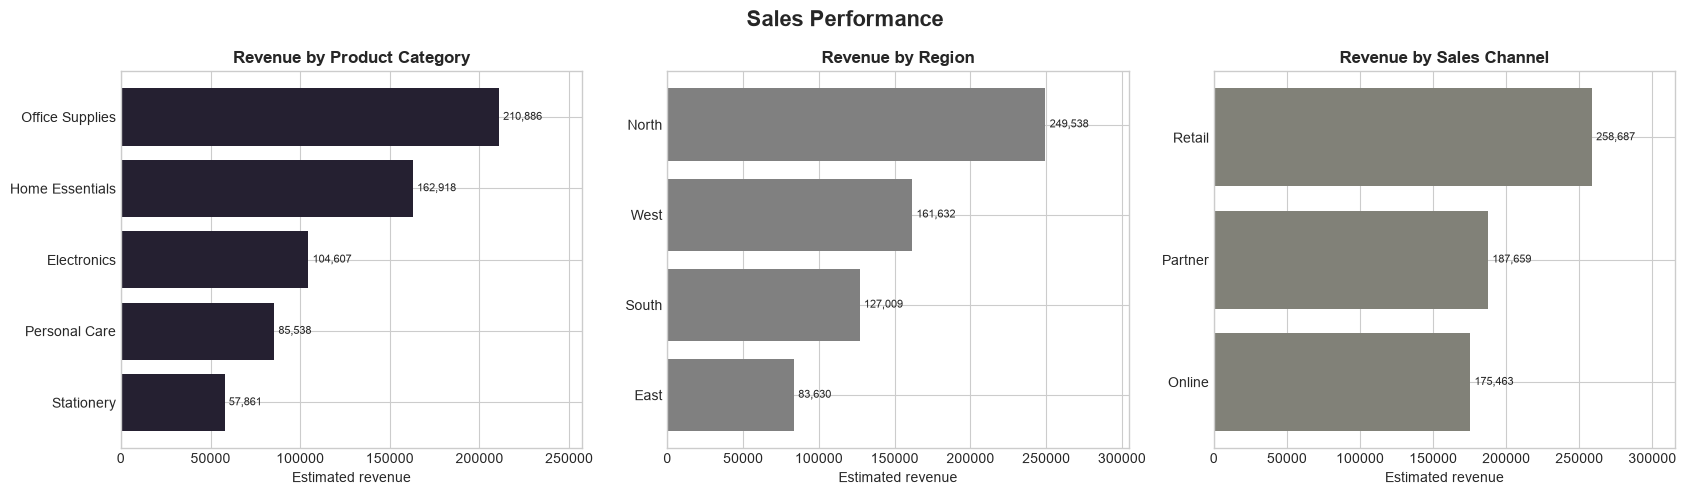

In [97]:
#Revenue by category, region, and channel
groups = ["Product Category", "Region", "Sales Channel"]
titles = ["Revenue by Product Category", "Revenue by Region", "Revenue by Sales Channel"]
colors = ["#252031", "grey", "#818178"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, group, title, color in zip(axes, groups, titles, colors):
    values = df.groupby(group)["Revenue"].sum().sort_values()
    bars = ax.barh(values.index, values.values, color=color)

    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel("Estimated revenue")
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values.values], padding=3, fontsize=8)
    ax.set_xlim(0, values.max() * 1.22)

fig.suptitle("Sales Performance", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

### Estimated Revenue Across the Business

- **Product category:** Office Supplies generated the most estimated revenue (210,886), followed by Home Essentials (162,918). Stationery generated the least (57,861)
- **Region:** North led with 249,538 in estimated revenue. East had the lowest total (83,630)
- **Sales channel:** Retail generated the most estimated revenue (258,687), followed by Partner (187,659) and Online (175,463)

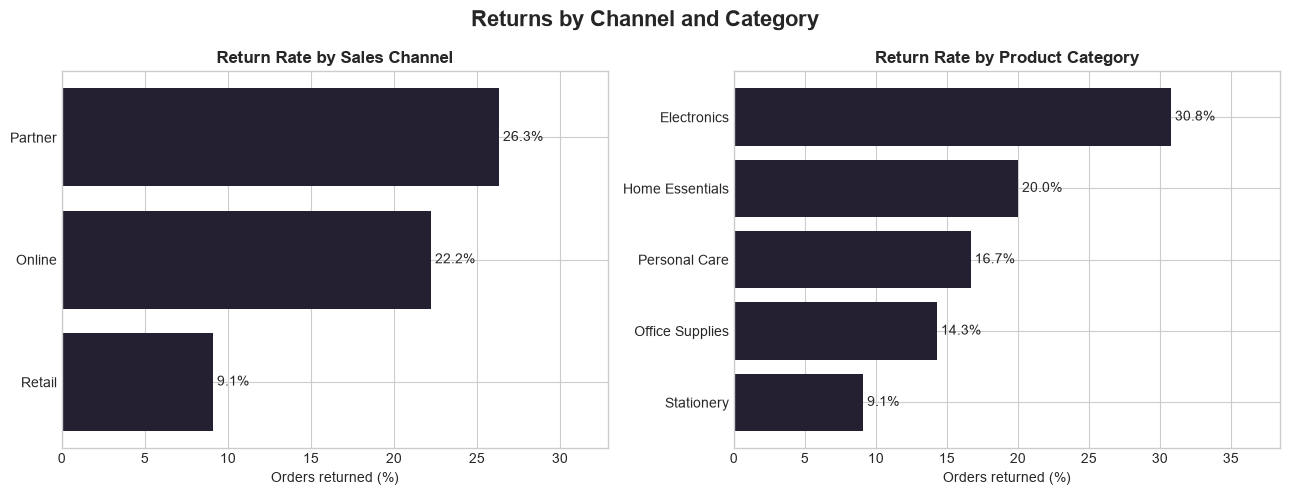

In [98]:
#Return rates by channel and category
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, group, title in zip(
    axes,
    ["Sales Channel", "Product Category"],
    ["Return Rate by Sales Channel", "Return Rate by Product Category"]
):
    rates = (
        df.groupby(group)["Returned Flag"]
          .mean()
          .mul(100)
          .sort_values()
    )

    bars = ax.barh(rates.index, rates.values, color="#252031")
    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel("Orders returned (%)")
    ax.set_xlim(0, max(rates.max() * 1.25, 5))
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in rates.values], padding=3)

fig.suptitle("Returns by Channel and Category", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

### Return Rates Across Channels and Categories

- **By channel:** Partner had the highest return rate (26.3%), while Retail had the lowest (9.1%).
- **By category:** Electronics had the highest return rate (30.8%), while Stationery had the lowest (9.1%).

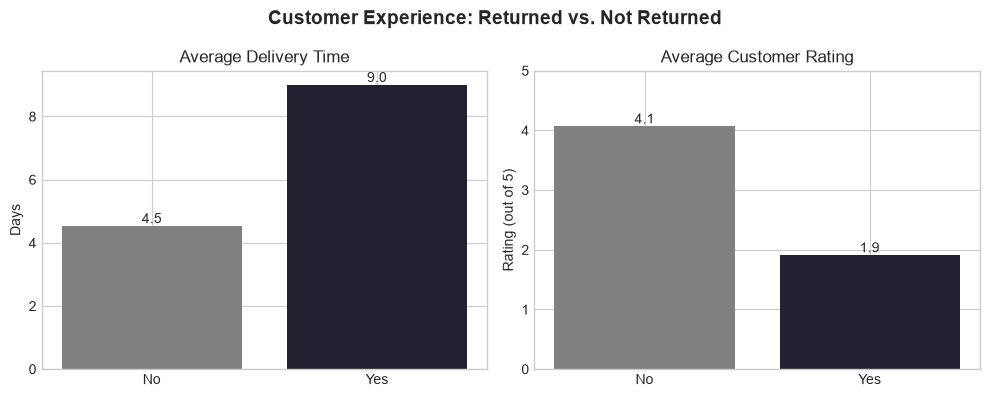

In [99]:
#Delivery time and customer ratings for returned vs. non-returned orders
summary = df.groupby("Returned?").agg(
    Avg_Delivery_Days=("Delivery Days", "mean"),
    Avg_Customer_Rating=("Customer Rating", "mean")
).reindex(["No", "Yes"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = ["grey", "#252031"]

bars = axes[0].bar(summary.index, summary["Avg_Delivery_Days"], color=colors)
axes[0].set_title("Average Delivery Time")
axes[0].set_ylabel("Days")
axes[0].bar_label(bars, fmt="%.1f")

bars = axes[1].bar(summary.index, summary["Avg_Customer_Rating"], color=colors)
axes[1].set_title("Average Customer Rating")
axes[1].set_ylabel("Rating (out of 5)")
axes[1].set_ylim(0, 5)
axes[1].bar_label(bars, fmt="%.1f")

fig.suptitle("Customer Experience: Returned vs. Not Returned", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

### Delivery and Ratings for Returned Orders

Returned orders averaged **9.0 delivery days** and a **1.9 customer rating**. Orders that were not returned averaged **4.5 delivery days** and a **4.1 rating**.

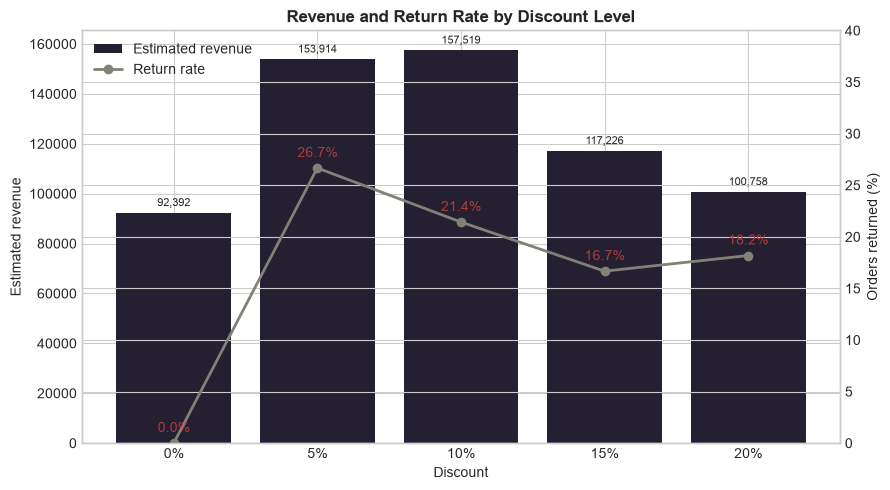

In [104]:
#Estimated revenue and return rate by discount
discount_summary = df.groupby("Discount %").agg(
    Revenue=("Revenue", "sum"),
    Return_Rate=("Returned Flag", "mean"),
    Orders=("Order ID", "nunique")
)

# Keep discount levels in numeric order
discount_order = sorted(
    discount_summary.index,
    key=lambda value: float(value.rstrip("%"))
)
discount_summary = discount_summary.reindex(discount_order)

fig, ax1 = plt.subplots(figsize=(9, 5))

x = np.arange(len(discount_summary))
bars = ax1.bar(x, discount_summary["Revenue"], color="#252031", label="Estimated revenue")
ax1.set_xticks(x, discount_summary.index)
ax1.set_xlabel("Discount")
ax1.set_ylabel("Estimated revenue")
ax1.set_title("Revenue and Return Rate by Discount Level", weight="bold")
ax1.bar_label(bars, labels=[f"{v:,.0f}" for v in discount_summary["Revenue"]], padding=3, fontsize=8)

ax2 = ax1.twinx()
ax2.plot(
    x,
    discount_summary["Return_Rate"] * 100,
    color="#818178",
    marker="o",
    linewidth=2,
    label="Return rate"
)
ax2.set_ylabel("Orders returned (%)")
ax2.set_ylim(0, 40)

for i, rate in enumerate(discount_summary["Return_Rate"] * 100):
    ax2.annotate(f"{rate:.1f}%", (i, rate), xytext=(0, 8),
                 textcoords="offset points", ha="center", color="#B23A3A")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

### Revenue and Returns by Discount Level

- The **10% discount** group had the highest estimated revenue (157,519); the **20% discount** group had the lowest (100,758).
- The **5% discount** group had the highest return rate (26.7%), while the no-discount group had no returns in this sample.

## Conclusion and Management Takeaways

This analysis covers **59 unique orders** after removing one exact duplicate. I standardized inconsistent capitalization, combined the `Office Supply` and `Office Supplies` labels, and filled two missing values using group averages. Revenue is estimated after discounts and **before returns or refunds**; refund amounts and product costs were not provided.

### Key findings

1. **Revenue differed across regions, channels, and categories.** North had the highest regional estimated revenue (249,538). Retail led the channels (258,687), and Office Supplies led the categories (210,886). These are revenue totals, not profit.
2. **Return rates varied across groups.** Partner had the highest channel return rate (26.3%), while Electronics had the highest category return rate (30.8%). Retail and Stationery had the lowest rates in their respective comparisons (both 9.1%).
3. **Returned orders also had longer delivery times and lower ratings.** Returned orders averaged 9.0 delivery days and a 1.9 rating, compared with 4.5 days and a 4.1 rating for orders not returned. This is an association in this sample, not proof that delivery time caused returns.

### Recommended follow-up

Review Partner and Electronics returns to identify common reasons, and investigate whether delivery delays are concentrated in particular orders or regions. Collect refund amounts, product costs, and more order history before drawing conclusions about net revenue, profit, or broader business trends.

**Limitations:** Results describe this small sample. Subgroup percentages can shift substantially with a few orders; treat them as leads for further analysis rather than proof of general trends.

In [105]:
df.to_csv("cleaned_orders_for_powerbi.csv", index=False)